In [1]:
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [9]:
model = YOLO("yolov8n.pt")

image_path = "../data/surveillance/cc3.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError("Surveillance image not found.")

output = image.copy()

In [22]:
h, w = image.shape[:2]

roi_points = np.array([
    [int(w * 0.28), int(h * 0.22)],
    [int(w * 0.72), int(h * 0.22)],
    [int(w * 0.78), int(h * 0.95)],
    [int(w * 0.22), int(h * 0.95)]
], dtype=np.int32)

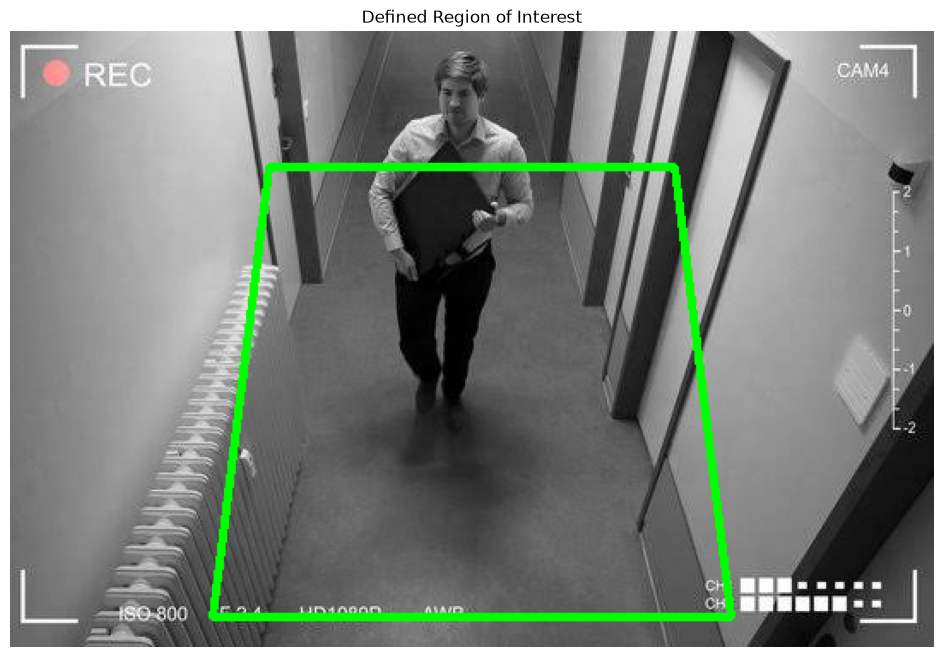

In [23]:
preview = image.copy()

cv2.polylines(
    preview,
    [roi_points],
    isClosed=True,
    color=(0, 255, 0),
    thickness=3
)

preview_rgb = cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(preview_rgb)
plt.title("Defined Region of Interest")
plt.axis("off")
plt.show()

In [24]:
results = model(image, verbose=False)

result = results[0]

In [25]:
intrusion_detected = False

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    # Only process persons
    if class_id == 0 and confidence >= 0.50:

        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].cpu().numpy()
        )

        # Calculate centroid
        cx = (x1 + x2) // 2
        cy = (y1 + y2) // 2

        # Test whether centroid lies inside ROI
        inside = cv2.pointPolygonTest(
            roi_points,
            (cx, cy),
            False
        )

        if inside >= 0:
            intrusion_detected = True

        # Draw bounding box
        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            (255, 0, 0),
            2
        )

        # Draw centroid
        cv2.circle(
            output,
            (cx, cy),
            6,
            (0, 255, 255),
            -1
        )

        label = f"Person {confidence:.2f}"

        cv2.putText(
            output,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

In [26]:
if intrusion_detected:
    roi_color = (0, 0, 255)   # Red in BGR
    status_text = "INTRUSION DETECTED"
else:
    roi_color = (0, 255, 0)   # Green
    status_text = "AREA SECURE"

In [27]:
cv2.polylines(
    output,
    [roi_points],
    isClosed=True,
    color=roi_color,
    thickness=4
)

array([[[119, 119, 119],
        [120, 120, 120],
        [121, 121, 121],
        ...,
        [112, 112, 112],
        [112, 112, 112],
        [111, 111, 111]],

       [[119, 119, 119],
        [120, 120, 120],
        [121, 121, 121],
        ...,
        [112, 112, 112],
        [112, 112, 112],
        [111, 111, 111]],

       [[120, 120, 120],
        [120, 120, 120],
        [122, 122, 122],
        ...,
        [112, 112, 112],
        [112, 112, 112],
        [112, 112, 112]],

       ...,

       [[ 99,  99,  99],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [ 81,  81,  81],
        [ 81,  81,  81],
        [ 81,  81,  81]],

       [[ 99,  99,  99],
        [ 99,  99,  99],
        [100, 100, 100],
        ...,
        [ 81,  81,  81],
        [ 81,  81,  81],
        [ 81,  81,  81]],

       [[ 99,  99,  99],
        [ 99,  99,  99],
        [100, 100, 100],
        ...,
        [ 81,  81,  81],
        [ 81,  81,  81],
        [ 81,  81,  81]]

In [28]:
cv2.rectangle(
    output,
    (0, 0),
    (output.shape[1], 70),
    roi_color,
    -1
)

cv2.putText(
    output,
    status_text,
    (25, 48),
    cv2.FONT_HERSHEY_SIMPLEX,
    1.2,
    (255, 255, 255),
    3
)

array([[[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       ...,

       [[ 99,  99,  99],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [ 81,  81,  81],
        [ 81,  81,  81],
        [ 81,  81,  81]],

       [[ 99,  99,  99],
        [ 99,  99,  99],
        [100, 100, 100],
        ...,
        [ 81,  81,  81],
        [ 81,  81,  81],
        [ 81,  81,  81]],

       [[ 99,  99,  99],
        [ 99,  99,  99],
        [100, 100, 100],
        ...,
        [ 81,  81,  81],
        [ 81,  81,  81],
        [ 81,  81,  81]]

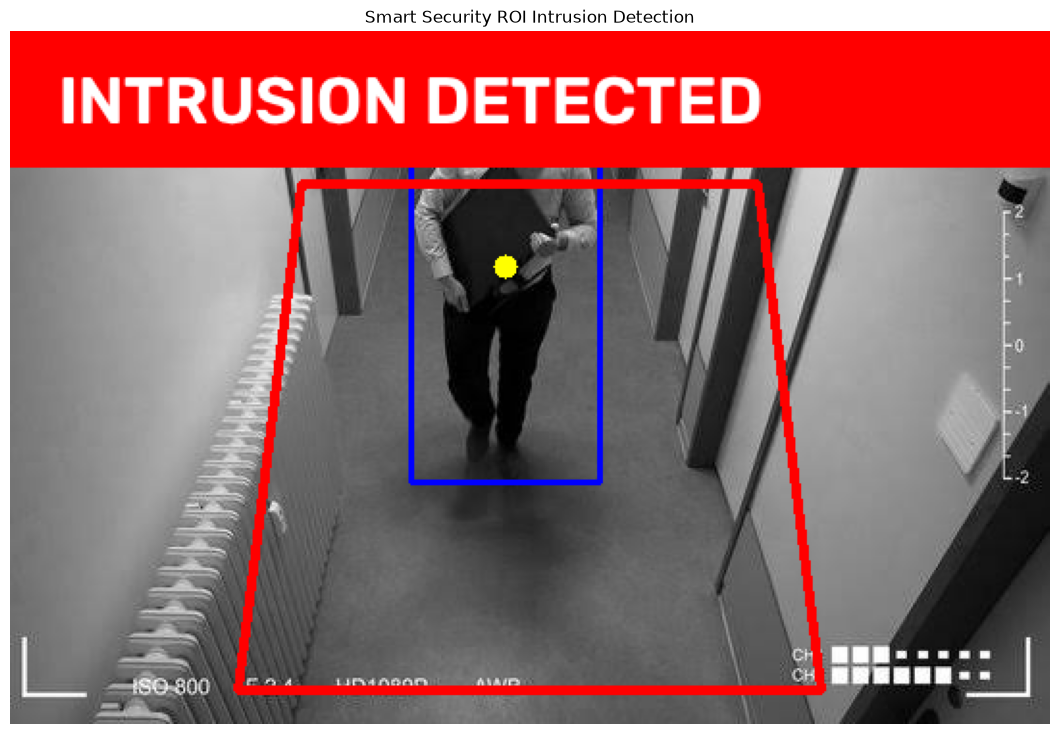

In [29]:
output_rgb = cv2.cvtColor(
    output,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 9))

plt.imshow(output_rgb)
plt.title("Smart Security ROI Intrusion Detection")
plt.axis("off")

plt.show()

In [30]:
cv2.imwrite(
    "../outputs/task6/intrusion_result.jpg",
    output
)

print("Saved to outputs/task6/intrusion_result.jpg")

Saved to outputs/task6/intrusion_result.jpg
